# 4. Hires by age (QWI): are young workers hired less in AI-exposed industries?

**Question:** Did hiring of 22–24 year olds fall relative to 35–44 year olds more in AI-exposed industries?

**How to use:** Run All. It shows the saved results in seconds. To recompute from the data, set `RUN = True` (about 2 minutes; needs the raw data in `data/raw/`, which isn't in the public repo; see the README).

In [1]:
from _nb import *

RUN = False
if RUN:
    run("sdid_qwi")


## How it works

- **Data:** Census QWI, actual hires from unemployment-insurance records, 27 industries × 4 regions.
- **Outcome:** log hires age 22–24 minus log hires age 35–44 in the same industry and region. Anything hitting the
  whole industry (like a rate shock) cancels.
- **Fixes along the way:** seasonality removed (young hiring is seasonal); standard errors clustered by industry.

## Results

In [2]:
r = results("sdid_qwi")
rows = {"2019 baseline (primary)": "primary_2019_baseline", "Late-2021 baseline": "secondary_late2021_baseline",
        "Dot-com bust (no AI)": "dotcom"}
display(pd.DataFrame({k: {"effect": pct(r[v]["gap"]["tau"]), "95% CI": ci(r[v]["gap"]["ci95"])} for k, v in rows.items()}).T)
print("When did it happen? Effect by year, pandemic quarters shown:")
by_year(r["exploratory_pandemic_kept"]["gap"]["by_year"])

,effect,95% CI
2019 baseline (primary),-9.3%,"[-18.3, -0.2]"
Late-2021 baseline,+0.1%,"[-5.3, +5.5]"
Dot-com bust (no AI),-2.9%,"[-9.7, +3.9]"


When did it happen? Effect by year, pandemic quarters shown:


,2020,2021,2022,2023,2024,2025
effect,-5.9%,-9.7%,-10.4%,-8.7%,-9.0%,-9.3%


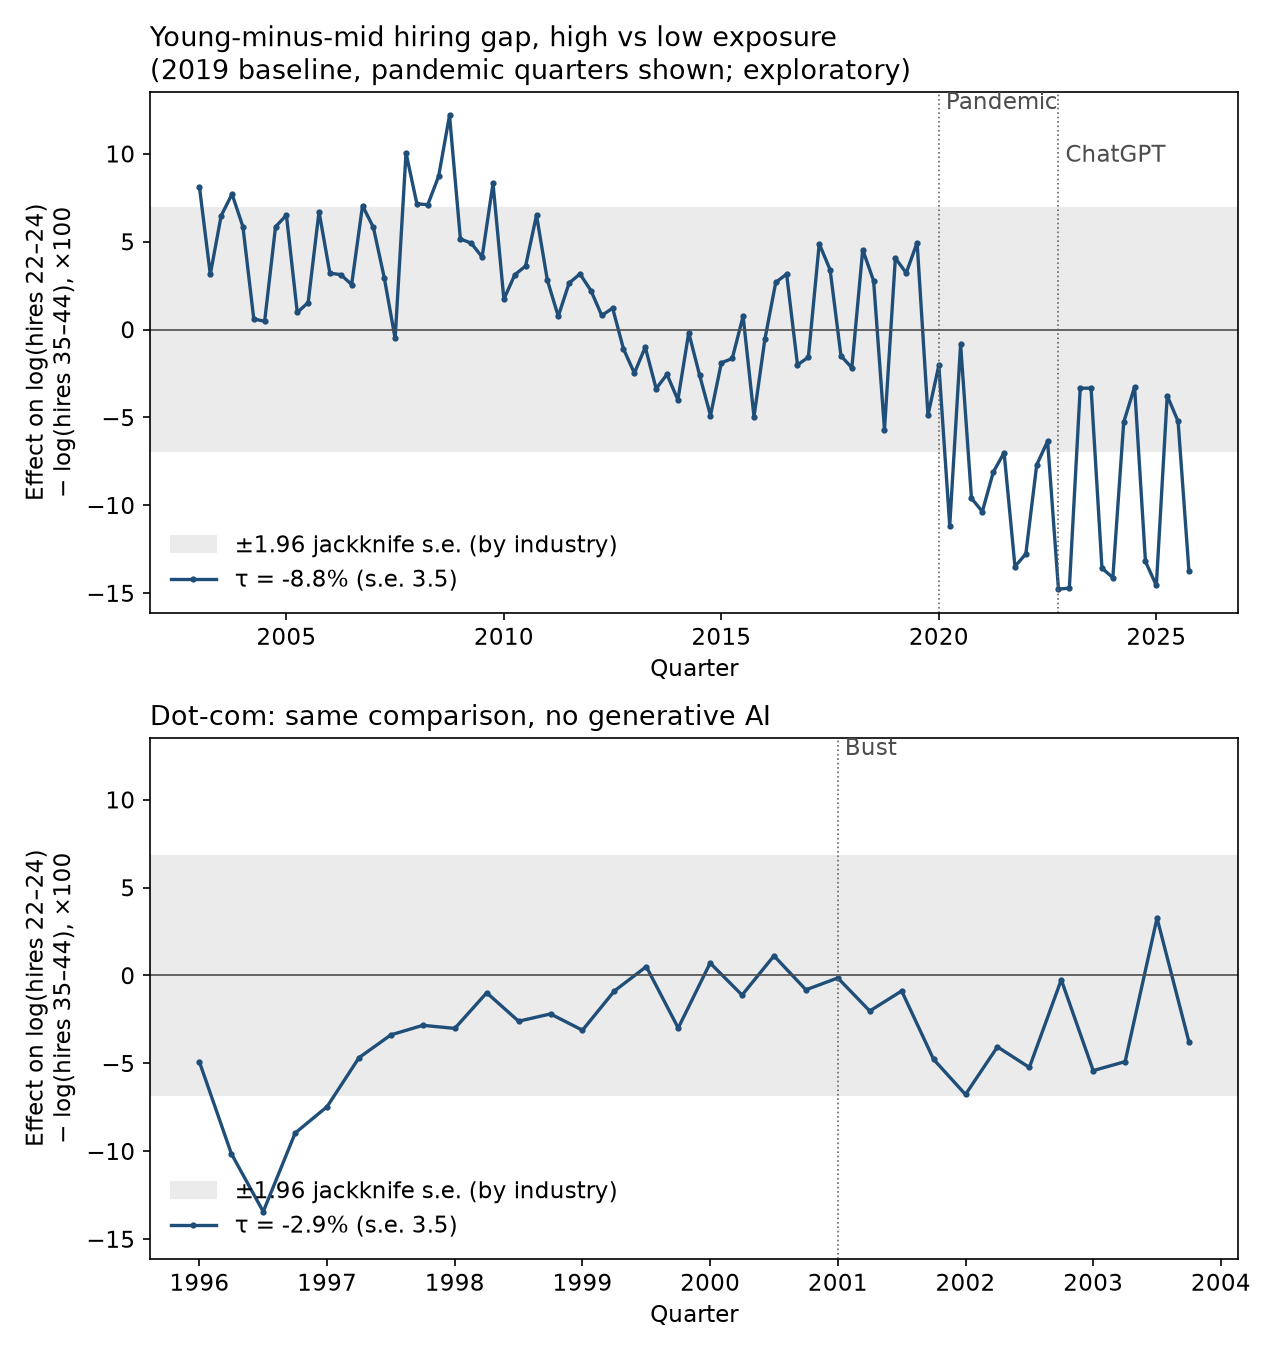

In [3]:
figure("fig_sdid_qwi")

## What it means

**A real early-career squeeze, but timed wrong for AI.** Young hiring fell about 9% relative to mid-career in
exposed industries (95% CI −18% to −0.2%). But the gap opened in 2020–21, before ChatGPT, and hasn't widened since. That points
to something that predates ChatGPT, such as the pandemic and remote work. **Lesson:** a real effect isn't automatically an AI effect; timing is the evidence.

---
Code: `scripts/sdid_qwi.py` · All results: `docs/SCORECARD.md` · Every decision: `docs/DECISIONS.md` · The whole story: `README.md`